Step 1 — Check the A40 and prepare the experiment folder

In [1]:
from pathlib import Path
import subprocess
import time

start = time.monotonic()
workspace = Path("/workspace")
root = workspace / "B3IT_Hidden_Input_Guard"

gpu = subprocess.check_output(
    ["nvidia-smi", "--query-gpu=name,memory.total,memory.free,driver_version",
     "--format=csv"],
    text=True,
).strip()
print(gpu)

if not workspace.is_mount():
    raise RuntimeError("Attach your RunPod volume at /workspace, then rerun this cell.")

print("\nWorkspace mount:")
subprocess.run(
    ["findmnt", "--mountpoint", str(workspace), "-o", "TARGET,SOURCE,FSTYPE"],
    check=True,
)

for folder in ("configs", "scripts", "logs", "data", "results"):
    (root / folder).mkdir(parents=True, exist_ok=True)

print(f"\nExperiment folder: {root}")
print(f"STEP 1 COMPLETE | {time.monotonic() - start:.1f} seconds")

name, memory.total [MiB], memory.free [MiB], driver_version
NVIDIA A40, 46068 MiB, 45490 MiB, 595.112.07

Workspace mount:
TARGET     SOURCE                                                  FSTYPE
/workspace mfs#eu-se-1.runpod.net:9421[/networkvolumes/flrv32qt7x] fuse

Experiment folder: /workspace/B3IT_Hidden_Input_Guard
STEP 1 COMPLETE | 0.0 seconds


Step 2 — Clone the B3IT repository

In [2]:
from pathlib import Path
import json
import subprocess
import time

start = time.monotonic()
root = Path("/workspace/B3IT_Hidden_Input_Guard")
repo = root / "repo"
url = "https://github.com/timothee-chauvin/token-efficient-change-detection-llm-apis.git"
commit = "ad2f69295797a5f03e7b480246080d91087d9007"

def git_output(*args):
    return subprocess.check_output(
        ["git", "-C", str(repo), *args], text=True
    ).strip()

if not repo.exists():
    subprocess.run(["git", "clone", "--no-checkout", url, str(repo)], check=True)
    subprocess.run(["git", "-C", str(repo), "checkout", "--detach", commit], check=True)

if not (repo / ".git").is_dir() or git_output("rev-parse", "HEAD") != commit:
    raise RuntimeError(f"The folder {repo} does not contain the expected B3IT checkout.")

sampler = repo / "track-llm-apis/src/track_llm_apis/sampling/vllm_sampling.py"
if not sampler.is_file():
    raise FileNotFoundError(f"Expected B3IT sampler is missing: {sampler}")

record = root / "configs/repository.json"
record.write_text(json.dumps({"url": url, "commit": commit}, indent=2) + "\n")

print("Repository:", repo)
print("Verified commit:", commit)
print("Saved:", record)
print(f"STEP 2 COMPLETE | {time.monotonic() - start:.1f} seconds")

Cloning into '/workspace/B3IT_Hidden_Input_Guard/repo'...


Repository: /workspace/B3IT_Hidden_Input_Guard/repo
Verified commit: ad2f69295797a5f03e7b480246080d91087d9007
Saved: /workspace/B3IT_Hidden_Input_Guard/configs/repository.json
STEP 2 COMPLETE | 2.7 seconds


HEAD is now at ad2f692 docs(demo): hold the last frame of the README recording for 10s (#2)


Step 3 — Create the experiment’s Python environment

In [3]:
from pathlib import Path
import os
import subprocess
import sys
import time

start = time.monotonic()
root = Path("/workspace/B3IT_Hidden_Input_Guard")
tools = root / "tools"
uv_dir = tools / "uv"
venv = root / ".venv"
python = venv / "bin/python"

env = {
    **os.environ,
    "UV_PYTHON_INSTALL_DIR": str(tools / "python"),
    "UV_CACHE_DIR": str(root / "cache/uv"),
    "UV_PYTHON_BIN_DIR": str(tools / "bin"),
}

if not python.exists():
    uv = uv_dir / "bin/uv"
    if not uv.is_file():
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--no-cache-dir",
             "--target", str(uv_dir), "uv==0.13.8"],
            check=True,
        )

    subprocess.run([str(uv), "python", "install", "3.11.18"], env=env, check=True)
    subprocess.run(
        [str(uv), "venv", "--managed-python", "--python", "3.11.18", str(venv)],
        env=env, check=True,
    )

subprocess.run(
    [str(python), "-c",
     "import sys; assert sys.version_info[:3] == (3, 11, 18), sys.version; "
     "print('Python:', sys.version.split()[0]); print('Environment:', sys.prefix)"],
    check=True,
)
print(f"STEP 3 COMPLETE | {time.monotonic() - start:.1f} seconds")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 158.7 MB/s  0:00:00


Installed Python 3.11.18 in 20.95s
 + cpython-3.11.18-linux-x86_64-gnu (python3.11)


Python: 3.11.18
Environment: /workspace/B3IT_Hidden_Input_Guard/.venv
STEP 3 COMPLETE | 24.0 seconds


Using CPython 3.11.18
Creating virtual environment at: B3IT_Hidden_Input_Guard/.venv
Activate with: source B3IT_Hidden_Input_Guard/.venv/bin/activate


Step 4 — Install the experiment dependencies and verify BF16

In [4]:
from pathlib import Path
import os
import subprocess
import time

start = time.monotonic()
root = Path("/workspace/B3IT_Hidden_Input_Guard")
uv = root / "tools/uv/bin/uv"
python = root / ".venv/bin/python"
package = root / "repo/track-llm-apis"
log_path = root / "logs/step4_install.log"

assert (package / "pyproject.toml").is_file(), f"Missing project at {package}"

env = {
    **os.environ,
    "UV_CACHE_DIR": str(root / "cache/uv"),
    "UV_LINK_MODE": "copy",
    "MPLBACKEND": "Agg",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
}

install = [
    str(uv), "pip", "install", "--python", str(python),
    "--index", "https://download.pytorch.org/whl/cu128",
    "--default-index", "https://pypi.org/simple",
    "--index-strategy", "unsafe-best-match",
    "-e", str(package),
    "torch==2.9.1+cu128", "vllm==0.15.0", "transformers==4.57.6",
    "lightning==2.6.1", "peft==0.18.1", "nvidia-modelopt[hf]==0.41.0",
]

verify = """
from importlib.metadata import version
import torch
from transformers import AutoTokenizer
from vllm import LLM
from track_llm_apis.config import config

for name in ("torch", "transformers", "vllm", "lightning", "track-llm-apis"):
    print(f"{name}: {version(name)}")

assert torch.cuda.is_available(), "PyTorch cannot access the GPU"
assert torch.cuda.is_bf16_supported(), "BF16 unavailable"
x = torch.ones((32, 32), device="cuda", dtype=torch.bfloat16)
assert (x @ x)[0, 0].item() == 32.0
print("BF16 calculation passed on", torch.cuda.get_device_name(0))
"""

with log_path.open("w") as log:
    for command in (install, [str(python), "-c", verify]):
        with subprocess.Popen(
            command, cwd=package, env=env, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
            if process.wait():
                raise RuntimeError(f"Step 4 stopped. See {log_path}")

print(f"STEP 4 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

Using Python 3.11.18 environment at: /workspace/B3IT_Hidden_Input_Guard/.venv
Resolved 230 packages in 8.77s
Prepared 230 packages in 1m 30s
Installed 230 packages in 2m 55s
 + accelerate==1.16.0
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.7
 + annotated-types==0.8.0
 + anthropic==2.10.0
 + anyio==4.16.0
 + apache-tvm-ffi==0.1.16
 + astor==0.8.1
 + attrs==26.1.0
 + beartype==0.23.1
 + blake3==1.0.11
 + cachetools==8.0.1
 + cbor2==6.3.0
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + choreographer==1.4.0
 + click==8.5.1
 + cloudpickle==3.1.3
 + compressed-tensors==0.13.0
 + contourpy==1.3.3
 + cryptography==50.0.2
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.9.0
 + cupy-cuda12x==14.2.0
 + cycler==0.12.1
 + datasets==5.0.1
 + deepspeed==0.20.0
 + depyf==0.20.0
 + detect-installer==0.2.1
 + diffusers==0.39.0
 + dill==0.4.1
 + diskcache==5.6.3
 + dnspython==2.9.2
 + docstring-parser==0.18.0
 + eino

Step 5 — Select 5,000 candidate questions

In [5]:
from pathlib import Path
import os
import subprocess
import time

start = time.monotonic()
root = Path("/workspace/B3IT_Hidden_Input_Guard")

prepare = """
import json
import random
from pathlib import Path
from datasets import load_dataset
from huggingface_hub import HfApi

root = Path.cwd()
path = root / "data/candidate_questions.json"
dataset_id = "PKU-Alignment/PKU-SafeRLHF"
seed = 0
count = 5000

if path.exists():
    record = json.loads(path.read_text())
    assert record["dataset"] == dataset_id and record["split"] == "train"
    assert record["seed"] == seed
    questions = record["questions"]
    print("Loaded saved candidate questions.")
else:
    revision = HfApi().dataset_info(dataset_id).sha
    dataset = load_dataset(dataset_id, "default", split="train", revision=revision)

    # Skip blanks and deduplicate by trimmed text. Keep the original prompt wording.
    unique = {}
    for prompt in dataset.select_columns(["prompt"])["prompt"]:
        if isinstance(prompt, str) and prompt.strip():
            unique.setdefault(prompt.strip(), prompt)

    if len(unique) < count:
        raise ValueError(f"Found only {len(unique)} unique questions.")

    questions = random.Random(seed).sample(list(unique.values()), count)
    record = {
        "dataset": dataset_id, "revision": revision, "split": "train",
        "column": "prompt", "seed": seed, "questions": questions,
    }
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(record, ensure_ascii=False, indent=2))
    temp.replace(path)

assert len(questions) == len({q.strip() for q in questions}) == count
print("Dataset revision:", record["revision"])
print("Verified unique candidate questions:", len(questions))
print("Saved:", path)
"""

subprocess.run(
    [str(root / ".venv/bin/python"), "-c", prepare],
    cwd=root,
    env={
        **os.environ,
        "HF_HOME": str(root / "cache/huggingface"),
        "HF_HUB_ENABLE_HF_TRANSFER": "0",
    },
    check=True,
)
print(f"STEP 5 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

Generating train split: 73907 examples [00:02, 29461.52 examples/s]
Generating test split: 8211 examples [00:00, 24409.41 examples/s]


Dataset revision: 9421ffafec3fa40a1f1a7d567b4d525079477ecb
Verified unique candidate questions: 5000
Saved: /workspace/B3IT_Hidden_Input_Guard/data/candidate_questions.json
STEP 5 COMPLETE | 0.4 minutes


Step 6 — Prepare background traffic for border-input discovery

In [6]:
from pathlib import Path
from getpass import getpass
import os
import subprocess
import time

start = time.monotonic()
root = Path("/workspace/B3IT_Hidden_Input_Guard")
cache = root / "data/datasets/lmsys2flmsys-chat-1m"
env = {
    **os.environ,
    "HF_HOME": str(root / "cache/huggingface"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
}

# LMSYS is gated. Use a read token from an account with dataset access.
if not cache.is_dir() and not env.get("HF_TOKEN"):
    env["HF_TOKEN"] = getpass("Hugging Face read token (hidden): ").strip()

prepare = """
from pathlib import Path
from track_llm_apis.config import config

config.data_dir = Path.cwd() / "data"
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts

traffic = _load_traffic_prompts()
if not traffic:
    raise RuntimeError("The repository loader returned no background requests.")
print("Background requests:", len(traffic))
print("Dataset directory:", config.datasets_dir)
"""

log_path = root / "logs/step6_traffic.log"
with log_path.open("w") as log:
    with subprocess.Popen(
        [str(root / ".venv/bin/python"), "-c", prepare],
        cwd=root, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait():
            raise RuntimeError(f"Traffic preparation failed. See {log_path}")

print(f"STEP 6 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

Hugging Face read token (hidden):  ········


2026-11-18 15:29:56,936 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-18 15:29:56,937 - track-llm-apis - INFO - No processed dataset found at /workspace/B3IT_Hidden_Input_Guard/data/datasets/lmsys2flmsys-chat-1m, creating...

Generating train split: 100%|██████████| 1000000/1000000 [00:17<00:00, 56646.92 examples/s]
2026-11-18 15:30:28,589 - track-llm-apis - INFO - Filtering dataset...

Filter: 100%|██████████| 1000000/1000000 [00:01<00:00, 947903.44 examples/s]

Map: 100%|██████████| 4570/4570 [00:07<00:00, 619.38 examples/s]

Filter: 100%|██████████| 4570/4570 [00:00<00:00, 70122.18 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 4502/4502 [00:00<00:00, 92806.83 examples/s]
2026-11-18 15:30:38,501 - track-llm-apis - INFO - Loaded 4502 traffic prompts
Background requests: 4502
Dataset directory: /workspace/B3IT_Hidden_Input_Guard/data/datasets
STEP 6 COMPLETE | 2.0 minutes


Step 7 — Discover border inputs with the guard off

In [7]:
from pathlib import Path
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
script = root / "scripts/discover.py"
log_path = root / "logs/step7_discovery.log"

script.write_text('''
import json
import random
import time
from pathlib import Path

from transformers import AutoTokenizer
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import (
    BIPhase1ModelResult,
    _load_traffic_prompts,
)
from track_llm_apis.sampling.vllm_sampling import vllm_inference_bi


def main():
    root = Path(__file__).resolve().parents[1]
    config.data_dir = root / "data"
    bi = config.sampling.bi
    model = "Qwen/Qwen2.5-0.5B-Instruct"
    revision = "7ae557604adf67be50417f59c2c2f167def9a775"
    system_prompt = "You are a helpful assistant."

    candidates = json.loads((root / "data/candidate_questions.json").read_text())
    questions = candidates["questions"]
    assert len(questions) == len(set(questions)) == 5000
    assert bi.phase_1_queries_per_token == 3 and bi.temperature == 0.0

    out = root / "results/discovery"
    out.mkdir(parents=True, exist_ok=True)
    path = out / "phase_1a.json"

    if path.exists():
        record = BIPhase1ModelResult.model_validate_json(path.read_bytes())
    else:
        tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)

        def format_request(text):
            return tokenizer.apply_chat_template(
                [{"role": "system", "content": system_prompt},
                 {"role": "user", "content": text}],
                tokenize=False,
                add_generation_prompt=True,
            )

        # Qwen receives the same chat format for candidates and background traffic.
        formatted = [format_request(q) for q in questions]
        traffic = [format_request(q) for q in _load_traffic_prompts()]
        print(f"Screening {len(questions)} questions × 3 with the guard off.", flush=True)

        llm = LLM(
            model=model, revision=revision, tokenizer_revision=revision,
            dtype="bfloat16", enforce_eager=True, enable_prefix_caching=False,
            gpu_memory_utilization=0.80, seed=0,
        )
        random.seed(0)
        started = time.monotonic()
        result = vllm_inference_bi(
            llm=llm, inputs=formatted, traffic_prompts=traffic,
            n_samples=bi.phase_1_queries_per_token, temperature=bi.temperature,
            input_fraction=bi.per_batch_input_fraction, batch_size=bi.batch_size,
            max_tokens=1,
        )

        # Save results under the original question text for calibration and testing.
        record = BIPhase1ModelResult(
            model_name=model, bi_config=bi.model_dump(mode="json"), phase="1a",
            results={q: result.counts[p] for q, p in zip(questions, formatted)},
            prompt_lengths={q: result.prompt_lengths[p] for q, p in zip(questions, formatted)},
            generation_time=time.monotonic() - started,
        )

    assert set(record.results) == set(questions)
    assert all(sum(counts.values()) == 3 for counts in record.results.values())

    if not path.exists():
        tmp = path.with_suffix(".tmp")
        tmp.write_text(record.model_dump_json())
        tmp.replace(path)

    borders = record.get_border_inputs()
    border_path = out / "border_candidates.json"
    border_path.write_text(json.dumps(borders, ensure_ascii=False, indent=2))
    print("Verified first-token observations:", 3 * len(questions))
    print("Border candidates found:", len(borders))
    print("Saved:", border_path)


if __name__ == "__main__":
    main()
'''.lstrip())

start = time.monotonic()
env = {
    **os.environ,
    "HF_HOME": str(root / "cache/huggingface"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
}
with log_path.open("w") as log:
    with subprocess.Popen(
        [str(root / ".venv/bin/python"), "-u", str(script)],
        cwd=root, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait():
            raise RuntimeError(f"Discovery stopped. See {log_path}")

print(f"STEP 7 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

[2026-11-18 15:32:39] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-18 15:32:39] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Hidden_Input_Guard/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-18 15:32:39] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
Screening 5000 questions × 3 with the guard off.
INFO 11-18 15:32:40 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-18 15:33:51 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-18 15:33:51 [model.py:1561] Using max model len 32768
INFO 11-18 15:33:54 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-18 15:33:54 [vllm.py:624] Asynchronous schedu

Step 8 — Calibrate the 190 border candidates

In [8]:
from pathlib import Path
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
script = root / "scripts/calibrate.py"

script.write_text('''
import json
import random
import time
from collections import Counter
from pathlib import Path

from transformers import AutoTokenizer
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import BIPhase1ModelResult, _load_traffic_prompts
from track_llm_apis.sampling.vllm_sampling import vllm_inference_bi


def save_text(path, text):
    temp = path.with_suffix(".tmp")
    temp.write_text(text)
    temp.replace(path)


def main():
    root = Path(__file__).resolve().parents[1]
    config.data_dir = root / "data"
    bi = config.sampling.bi
    discovery = root / "results/discovery/phase_1a.json"
    previous = BIPhase1ModelResult.model_validate_json(discovery.read_bytes())
    questions = previous.get_border_inputs()
    if not questions:
        raise ValueError("Discovery contains no border candidates.")

    model = previous.model_name
    revision = "7ae557604adf67be50417f59c2c2f167def9a775"
    rounds = bi.phase_1_queries_per_bi
    assert rounds == 1000 and bi.temperature == 0.0
    block_size = 100

    out = root / "results/calibration"
    blocks = out / "blocks"
    blocks.mkdir(parents=True, exist_ok=True)

    tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)

    def format_request(text):
        return tokenizer.apply_chat_template(
            [{"role": "system", "content": "You are a helpful assistant."},
             {"role": "user", "content": text}],
            tokenize=False, add_generation_prompt=True,
        )

    formatted = [format_request(q) for q in questions]
    traffic = [format_request(q) for q in _load_traffic_prompts()]
    totals = {q: Counter() for q in questions}
    seconds = 0.0
    llm = None

    for start in range(0, rounds, block_size):
        path = blocks / f"rounds_{start:04d}.json"
        if path.exists():
            block = json.loads(path.read_text())
        else:
            if llm is None:
                llm = LLM(
                    model=model, revision=revision, tokenizer_revision=revision,
                    dtype="bfloat16", enforce_eager=True, enable_prefix_caching=False,
                    gpu_memory_utilization=0.80, seed=0,
                )

            random.seed(10_000 + start)
            began = time.monotonic()
            result = vllm_inference_bi(
                llm=llm, inputs=formatted, traffic_prompts=traffic,
                n_samples=block_size, temperature=bi.temperature,
                input_fraction=bi.per_batch_input_fraction,
                batch_size=bi.batch_size, max_tokens=1,
            )
            block = {
                "counts": {q: result.counts[p] for q, p in zip(questions, formatted)},
                "seconds": time.monotonic() - began,
            }

        counts = block["counts"]
        if counts.keys() != totals.keys() or any(sum(c.values()) != block_size for c in counts.values()):
            raise ValueError(f"Incomplete or mismatched calibration block: {path}")

        if not path.exists():
            save_text(path, json.dumps(block, ensure_ascii=False))
        for q in questions:
            totals[q].update(counts[q])
        seconds += block["seconds"]
        print(f"Verified {start + block_size}/{rounds} rounds", flush=True)

    assert all(sum(c.values()) == rounds for c in totals.values())
    record = BIPhase1ModelResult(
        model_name=model, bi_config=bi.model_dump(mode="json"), phase="1b",
        results=totals,
        prompt_lengths={q: previous.prompt_lengths[q] for q in questions},
        generation_time=seconds,
    )
    confirmed = record.get_border_inputs()
    save_text(out / "phase_1b.json", record.model_dump_json())
    save_text(out / "confirmed_questions.json", json.dumps(confirmed, ensure_ascii=False, indent=2))
    print("Verified calibration observations:", len(questions) * rounds)
    print(f"Varied again: {len(confirmed)}/{len(questions)}")
    print("Saved:", out / "confirmed_questions.json")


if __name__ == "__main__":
    main()
'''.lstrip())

start = time.monotonic()
env = {
    **os.environ,
    "HF_HOME": str(root / "cache/huggingface"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
}
log_path = root / "logs/step8_calibration.log"
with log_path.open("a") as log:
    with subprocess.Popen(
        [str(root / ".venv/bin/python"), "-u", str(script)],
        cwd=root, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait():
            raise RuntimeError(f"Calibration stopped. See {log_path}")

print(f"STEP 8 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

[2026-11-18 15:38:23] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-18 15:38:23] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Hidden_Input_Guard/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-18 15:38:23] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
INFO 11-18 15:38:24 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-18 15:38:25 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-18 15:38:25 [model.py:1561] Using max model len 32768
INFO 11-18 15:38:27 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-18 15:38:27 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-18 15:38:27 [vllm.py:

Step 9 — Select and save the 120 test probes

from pathlib import Path
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
start = time.monotonic()

select_probes = """
import json
from pathlib import Path
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import BIPhase1ModelResult

root = Path.cwd()
calibration = root / "results/calibration/phase_1b.json"
record = BIPhase1ModelResult.model_validate_json(calibration.read_bytes())

confirmed = record.get_border_inputs()
limit = config.sampling.bi.max_border_inputs
assert limit == 120
probes = confirmed[:limit]
assert len(set(probes)) == 120
assert all(sum(record.results[q].values()) == 1000 for q in probes)

path = root / "results/detection/probes.json"
path.parent.mkdir(parents=True, exist_ok=True)

if path.exists():
    if json.loads(path.read_text()) != probes:
        raise RuntimeError("The saved probe list differs from this selection.")
else:
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(probes, ensure_ascii=False, indent=2))
    temp.replace(path)

print("Confirmed border inputs:", len(confirmed))
print("Selected test probes:", len(probes))
print("Saved:", path)
"""

subprocess.run(
    [str(root / ".venv/bin/python"), "-c", select_probes],
    cwd=root, check=True,
)
print(f"STEP 9 COMPLETE | {time.monotonic() - start:.1f} seconds")

Step 10 — Collect the guard-off baseline

In [10]:
from pathlib import Path
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
script = root / "scripts/collect_baseline.py"

script.write_text('''
import gzip
import json
import random
import time
from pathlib import Path

from transformers import AutoTokenizer
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts
from track_llm_apis.sampling.vllm_sampling import vllm_inference_bi


def main():
    root = Path(__file__).resolve().parents[1]
    config.data_dir = root / "data"
    bi = config.sampling.bi
    probes = json.loads((root / "results/detection/probes.json").read_text())
    assert len(probes) == len(set(probes)) == 120

    out = root / "results/detection/original"
    out.mkdir(parents=True, exist_ok=True)
    plan = {
        "condition": "guard_off",
        "model": "Qwen/Qwen2.5-0.5B-Instruct",
        "revision": "7ae557604adf67be50417f59c2c2f167def9a775",
        "system_prompt": "You are a helpful assistant.",
        "probes_in_column_order": probes,
        "rounds": 5000,
        "block_size": 250,
        "round_seed_base": 200000,
        "temperature": bi.temperature,
        "batch_size": bi.batch_size,
        "input_fraction": bi.per_batch_input_fraction,
        "max_tokens": 1,
    }
    manifest = out / "settings.json"
    if manifest.exists():
        if json.loads(manifest.read_text()) != plan:
            raise RuntimeError("Saved baseline settings differ from this run.")
    else:
        temp = manifest.with_suffix(".tmp")
        temp.write_text(json.dumps(plan, ensure_ascii=False, indent=2))
        temp.replace(manifest)

    tokenizer = AutoTokenizer.from_pretrained(plan["model"], revision=plan["revision"])

    def format_request(text):
        return tokenizer.apply_chat_template(
            [{"role": "system", "content": plan["system_prompt"]},
             {"role": "user", "content": text}],
            tokenize=False, add_generation_prompt=True,
        )

    inputs = [format_request(q) for q in probes]
    traffic = [format_request(q) for q in _load_traffic_prompts()]
    llm = None
    verified = 0

    for start in range(0, plan["rounds"], plan["block_size"]):
        stop = min(start + plan["block_size"], plan["rounds"])
        path = out / f"rounds_{start:04d}.json.gz"
        if path.exists():
            with gzip.open(path, "rt") as f:
                rows = json.load(f)
        else:
            if llm is None:
                llm = LLM(
                    model=plan["model"], revision=plan["revision"],
                    tokenizer_revision=plan["revision"], dtype="bfloat16",
                    enforce_eager=True, enable_prefix_caching=False,
                    gpu_memory_utilization=0.80, seed=0,
                )

            rows = []
            began = time.monotonic()
            for i in range(start, stop):
                random.seed(plan["round_seed_base"] + i)
                result = vllm_inference_bi(
                    llm=llm, inputs=inputs, traffic_prompts=traffic,
                    n_samples=1, temperature=plan["temperature"],
                    input_fraction=plan["input_fraction"],
                    batch_size=plan["batch_size"], max_tokens=1,
                )
                row = []
                for prompt in inputs:
                    counts = result.counts[prompt]
                    if len(counts) != 1 or sum(counts.values()) != 1:
                        raise ValueError(f"Expected one observation in round {i}.")
                    row.append(next(iter(counts)))
                rows.append(row)

            temp = path.with_suffix(".tmp")
            with gzip.open(temp, "wt", encoding="utf-8") as f:
                json.dump(rows, f, ensure_ascii=False)
            temp.replace(path)
            elapsed = time.monotonic() - began
            print(f"Saved {stop}/5000 | about {elapsed * (5000-stop) / (stop-start) / 60:.1f} min left",
                  flush=True)

        if len(rows) != stop-start or any(len(row) != len(probes) for row in rows):
            raise ValueError(f"Incomplete block: {path}")
        verified += len(rows) * len(probes)

    assert verified == 600000
    print("Verified baseline observations:", verified)
    print("Saved:", out)


if __name__ == "__main__":
    main()
'''.lstrip())

start = time.monotonic()
env = {
    **os.environ,
    "HF_HOME": str(root / "cache/huggingface"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
}
log_path = root / "logs/step10_baseline.log"
with log_path.open("a") as log:
    with subprocess.Popen(
        [str(root / ".venv/bin/python"), "-u", str(script)],
        cwd=root, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait():
            raise RuntimeError(f"Baseline collection stopped. See {log_path}")

print(f"STEP 10 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

[2026-11-18 16:05:25] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-18 16:05:25] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Hidden_Input_Guard/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-18 16:05:26] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
INFO 11-18 16:05:26 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-18 16:05:27 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-18 16:05:27 [model.py:1561] Using max model len 32768
INFO 11-18 16:05:28 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-18 16:05:28 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-18 16:05:28 [vllm.py:

Step 11 — Classify the requests with the hidden guard

In [11]:
from pathlib import Path
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
script = root / "scripts/classify_guard.py"

script.write_text(r'''
import json
import re
from collections import Counter
from pathlib import Path

from huggingface_hub import HfApi
from transformers import AutoTokenizer
from vllm import LLM, SamplingParams
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts


def save_json(path, value):
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2))
    temp.replace(path)


def main():
    root = Path(__file__).resolve().parents[1]
    config.data_dir = root / "data"
    probes = json.loads((root / "results/detection/probes.json").read_text())
    traffic = list(_load_traffic_prompts())
    assert len(set(probes)) == len(probes) == 120
    requests = list(dict.fromkeys([*probes, *traffic]))

    out = root / "results/guard"
    out.mkdir(parents=True, exist_ok=True)
    model = "Qwen/Qwen3Guard-Gen-0.6B"
    settings_path = out / "settings.json"
    if settings_path.exists():
        revision = json.loads(settings_path.read_text())["revision"]
    else:
        revision = HfApi().model_info(model).sha

    settings = {
        "model": model, "revision": revision, "dtype": "bfloat16",
        "temperature": 0.0, "max_guard_output_tokens": 32,
        "trigger_label": "Unsafe", "prefix": "unsafe question ",
    }
    if settings_path.exists() and json.loads(settings_path.read_text()) != settings:
        raise RuntimeError("Existing guard decisions use different settings.")
    save_json(settings_path, settings)

    path = out / "decisions.json"
    decisions = json.loads(path.read_text()) if path.exists() else {}
    allowed = {"Safe", "Unsafe", "Controversial"}
    if not set(decisions).issubset(requests) or any(
        label not in allowed for label in decisions.values()
    ):
        raise ValueError("The saved guard decisions do not match this experiment.")

    pending = [q for q in requests if q not in decisions]
    print(f"Unique requests: {len(requests)} | remaining: {len(pending)}", flush=True)

    if pending:
        tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)
        llm = LLM(
            model=model, revision=revision, tokenizer_revision=revision,
            dtype="bfloat16", enforce_eager=True,
            gpu_memory_utilization=0.80, seed=0,
        )
        params = SamplingParams(temperature=0.0, max_tokens=32)
        label_line = re.compile(
            r"^\s*Safety:\s*(Safe|Unsafe|Controversial)\s*$", re.MULTILINE
        )

        for start in range(0, len(pending), 128):
            batch = pending[start:start + 128]
            # Use the guard's own user-prompt moderation template.
            inputs = [
                {"prompt_token_ids": tokenizer.apply_chat_template(
                    [{"role": "user", "content": q}],
                    tokenize=True, add_generation_prompt=False,
                )}
                for q in batch
            ]
            outputs = llm.generate(inputs, params, use_tqdm=False)
            for q, output in zip(batch, outputs, strict=True):
                reply = output.outputs[0].text
                match = label_line.search(reply)
                if match is None:
                    raise ValueError(f"Could not read the guard's safety label: {reply!r}")
                decisions[q] = match.group(1)

            save_json(path, decisions)
            print(f"Saved {len(decisions)}/{len(requests)} decisions", flush=True)

    assert set(decisions) == set(requests)
    probe_counts = Counter(decisions[q] for q in probes)
    traffic_counts = Counter(decisions[q] for q in traffic)
    print("Probe labels:", dict(probe_counts))
    print("Background labels:", dict(traffic_counts))
    print(f"Probes that will receive the prefix: {probe_counts['Unsafe']}/{len(probes)}")
    print("Saved:", path)


if __name__ == "__main__":
    main()
'''.lstrip())

start = time.monotonic()
env = {
    **os.environ,
    "HF_HOME": str(root / "cache/huggingface"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
}
log_path = root / "logs/step11_guard.log"
with log_path.open("a") as log:
    with subprocess.Popen(
        [str(root / ".venv/bin/python"), "-u", str(script)],
        cwd=root, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait():
            raise RuntimeError(f"Guard classification stopped. See {log_path}")

print(f"STEP 11 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

[2026-11-18 16:25:20] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-18 16:25:20] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Hidden_Input_Guard/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-18 16:25:20] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
Unique requests: 4046 | remaining: 4046
INFO 11-18 16:25:24 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': 'fada3b2f655b89601929198343c94cd2f64d93cc', 'tokenizer_revision': 'fada3b2f655b89601929198343c94cd2f64d93cc', 'enforce_eager': True, 'model': 'Qwen/Qwen3Guard-Gen-0.6B'}
INFO 11-18 16:26:23 [model.py:541] Resolved architecture: Qwen3ForCausalLM
INFO 11-18 16:26:23 [model.py:1561] Using max model len 32768
INFO 11-18 16:26:25 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-18 16:26:25 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-18 16:26:25 [vl

Step 12 — Collect the guard-on observations

In [12]:
from pathlib import Path
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
source = (root / "scripts/collect_baseline.py").read_text()

# Derive the guarded collector from the exact baseline script used in Step 10.
def replace_once(text, old, new):
    if text.count(old) != 1:
        raise RuntimeError(f"Baseline script differs from Step 10 near {old!r}")
    return text.replace(old, new, 1)

source = replace_once(source, "import gzip", "import gzip\nimport hashlib")
source = replace_once(
    source,
    'out = root / "results/detection/original"',
    '''guard_dir = root / "results/guard"
    guard_settings = json.loads((guard_dir / "settings.json").read_text())
    decision_bytes = (guard_dir / "decisions.json").read_bytes()
    decisions = json.loads(decision_bytes)
    prefix = guard_settings["prefix"]
    assert prefix == "unsafe question " and guard_settings["trigger_label"] == "Unsafe"
    assert all(label in {"Safe", "Unsafe", "Controversial"} for label in decisions.values())
    flagged = sum(decisions[q] == "Unsafe" for q in probes)
    print(f"Applying the prefix to {flagged}/{len(probes)} probes.", flush=True)
    out = root / "results/detection/guard_on"''',
)
source = replace_once(
    source,
    '"condition": "guard_off",',
    '''"condition": "guard_on",
        "guard": guard_settings,
        "guard_decisions_sha256": hashlib.sha256(decision_bytes).hexdigest(),''',
)
source = replace_once(
    source,
    "def format_request(text):",
    '''def format_request(text):
        # This function handles both probes and background traffic.
        if decisions[text] == "Unsafe":
            text = prefix + text''',
)
source = replace_once(
    source, "Verified baseline observations:", "Verified guard-on observations:"
)

script = root / "scripts/collect_guard_on.py"
compile(source, str(script), "exec")
script.write_text(source)

start = time.monotonic()
env = {
    **os.environ,
    "HF_HOME": str(root / "cache/huggingface"),
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "MPLBACKEND": "Agg",
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
}
log_path = root / "logs/step12_guard_on.log"
with log_path.open("a") as log:
    with subprocess.Popen(
        [str(root / ".venv/bin/python"), "-u", str(script)],
        cwd=root, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        if process.wait():
            raise RuntimeError(f"Guard-on collection stopped. See {log_path}")

print(f"STEP 12 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

Applying the prefix to 78/120 probes.
[2026-11-18 16:30:21] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-18 16:30:21] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Hidden_Input_Guard/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-18 16:30:21] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
INFO 11-18 16:30:22 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-18 16:30:22 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-18 16:30:22 [model.py:1561] Using max model len 32768
INFO 11-18 16:30:23 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-18 16:30:23 [vllm.py:624] Asynchronous scheduling is ena

Step 13 — Merge the baseline and guard-on observations for scoring

In [13]:
from pathlib import Path
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
script = root / "scripts/merge_detection.py"

script.write_text('''
import gzip
import json
from collections import Counter
from pathlib import Path

from track_llm_apis.sampling.common import CompressedOutput
from track_llm_apis.tinychange import TinyChange


def main():
    root = Path(__file__).resolve().parents[1]
    detection = root / "results/detection"
    probes = json.loads((detection / "probes.json").read_text())
    assert len(probes) == len(set(probes)) == 120

    def settings(condition):
        return json.loads((detection / condition / "settings.json").read_text())

    baseline = settings("original")
    guarded = settings("guard_on")
    assert baseline["condition"] == "guard_off" and guarded["condition"] == "guard_on"
    for key in (
        "model", "revision", "system_prompt", "probes_in_column_order",
        "rounds", "block_size", "round_seed_base", "temperature",
        "batch_size", "input_fraction", "max_tokens",
    ):
        if baseline[key] != guarded[key]:
            raise ValueError(f"Collection settings differ for {key}")

    assert baseline["probes_in_column_order"] == probes
    assert baseline["rounds"] == 5000 and baseline["max_tokens"] == 1

    # Use the original request as the probe identity in both conditions.
    # These lengths describe baseline requests and exclude the hidden guard's costs.
    calibration = json.loads((root / "results/calibration/phase_1b.json").read_text())
    lengths = {q: calibration["prompt_lengths"][q] for q in probes}

    labels = {
        "original": TinyChange.unchanged_str(),
        "guard_on": json.dumps({
            "type": "hidden_input_guard",
            "model": guarded["guard"]["model"],
            "trigger": "Unsafe",
            "prefix": guarded["guard"]["prefix"],
        }),
    }
    merged = CompressedOutput(model_name=baseline["model"], gpus=["NVIDIA A40"])
    rounds, block_size = baseline["rounds"], baseline["block_size"]

    for condition, label in labels.items():
        counts = {q: Counter() for q in probes}
        for start in range(0, rounds, block_size):
            path = detection / condition / f"rounds_{start:04d}.json.gz"
            with gzip.open(path, "rt", encoding="utf-8") as f:
                rows = json.load(f)

            if len(rows) != min(block_size, rounds - start):
                raise ValueError(f"Unexpected round count in {path}")
            for row in rows:
                for q, token in zip(probes, row, strict=True):
                    if not isinstance(token, str):
                        raise ValueError(f"Invalid token in {path}")
                    counts[q][token] += 1

        assert all(sum(c.values()) == rounds for c in counts.values())
        merged.add_bi_results(counts, lengths, label, output_tokens=1)
        print(f"Verified {condition}: {len(probes)} × {rounds} = 600,000", flush=True)

    assert len(merged.rows) == 1_200_000
    out = detection / "merged"
    merged.dump_json(out)
    (out / "condition_mapping.json").write_text(json.dumps(labels, indent=2))
    print("Merged observations:", len(merged.rows))
    print("Saved:", out)


if __name__ == "__main__":
    main()
'''.lstrip())

start = time.monotonic()
subprocess.run([str(root / ".venv/bin/python"), "-u", str(script)], cwd=root, check=True)
print(f"STEP 13 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

Traceback (most recent call last):
  File "/workspace/B3IT_Hidden_Input_Guard/scripts/merge_detection.py", line 7, in <module>
    from track_llm_apis.tinychange import TinyChange
  File "/workspace/B3IT_Hidden_Input_Guard/repo/track-llm-apis/src/track_llm_apis/tinychange.py", line 11, in <module>
    import lightning as pl
  File "/workspace/B3IT_Hidden_Input_Guard/.venv/lib/python3.11/site-packages/lightning/__init__.py", line 18, in <module>
    from lightning.fabric.fabric import Fabric  # noqa: E402
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/workspace/B3IT_Hidden_Input_Guard/.venv/lib/python3.11/site-packages/lightning/fabric/__init__.py", line 35, in <module>
    from lightning.fabric.fabric import Fabric  # noqa: E402
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/workspace/B3IT_Hidden_Input_Guard/.venv/lib/python3.11/site-packages/lightning/fabric/fabric.py", line 39, in <module>
    from lightning.fabric.accelerators.accelerator import Accelerator
  File 

CalledProcessError: Command '['/workspace/B3IT_Hidden_Input_Guard/.venv/bin/python', '-u', '/workspace/B3IT_Hidden_Input_Guard/scripts/merge_detection.py']' returned non-zero exit status 1.

In [14]:
from pathlib import Path
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
start = time.monotonic()

subprocess.run(
    [str(root / ".venv/bin/python"), "-u", str(root / "scripts/merge_detection.py")],
    cwd=root,
    env={**os.environ, "MPLBACKEND": "Agg"},
    check=True,
)

print(f"STEP 13 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

2026-11-18 16:49:07,123 - matplotlib.font_manager - INFO - generated new fontManager


Verified original: 120 × 5000 = 600,000
Verified guard_on: 120 × 5000 = 600,000
Merged observations: 1200000
Saved: /workspace/B3IT_Hidden_Input_Guard/results/detection/merged
STEP 13 COMPLETE | 1.8 minutes


In [ ]:
Step 14 — Score hidden-guard detection with B3IT

In [16]:
from pathlib import Path
import ast
import os
import subprocess
import time

root = Path("/workspace/B3IT_Hidden_Input_Guard")
module = root / "repo/track-llm-apis/src/track_llm_apis/sampling/common.py"
source = module.read_text()

# Keep the repository's naming logic. Escape path separators in the final filename.
helper = "_get_variant_filename_before_escaping"
if f"def {helper}(" not in source:
    tree = ast.parse(source)
    func = next(
        node for node in tree.body
        if isinstance(node, ast.FunctionDef) and node.name == "get_variant_filename"
    )
    lines = source.splitlines(keepends=True)
    original = "".join(lines[func.lineno - 1:func.end_lineno])
    renamed = original.replace("def get_variant_filename(", f"def {helper}(", 1)

    wrapper = '''
def get_variant_filename(variant: str, params: dict[str, int | float] | None = None) -> str:
    filename = _get_variant_filename_before_escaping(variant, params)
    return filename.replace("%", "%25").replace("/", "%2F")
'''
    lines[func.lineno - 1:func.end_lineno] = [renamed, "\n", wrapper, "\n"]
    updated = "".join(lines)
    compile(updated, str(module), "exec")
    module.write_text(updated)

start = time.monotonic()
subprocess.run(
    [str(root / ".venv/bin/python"), "-u", str(root / "scripts/score_b3it.py")],
    cwd=root,
    env={**os.environ, "MPLBACKEND": "Agg", "PYTHONHASHSEED": "42"},
    check=True,
)
print(f"STEP 14 COMPLETE | {(time.monotonic() - start) / 60:.1f} minutes")

2026-11-18 17:01:13,102 - track-llm-apis - INFO - Searching for a .json.gz file in /workspace/B3IT_Hidden_Input_Guard/results/detection/merged...
2026-11-18 17:01:13,103 - track-llm-apis - INFO - Decompressing /workspace/B3IT_Hidden_Input_Guard/results/detection/merged/Qwen2fQwen2.5-0.5B-Instruct.json.gz...
2026-11-18 17:01:13,104 - track-llm-apis - INFO - Loading JSON data from contents of the file...
2026-11-18 17:01:14,674 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-18 17:01:21,231 - track-llm-apis - INFO - B3IT: Building shared vocabulary across all variants...
2026-11-18 17:01:22,369 - track-llm-apis - INFO - B3IT: Precomputing counts for unchanged model...
2026-11-18 17:01:31,153 - track-llm-apis - INFO - B3IT: Precomputing counts for all variants...
2026-11-18 17:01:39,532 - track-llm-apis - INFO - Computing stats for n_prompts=5, detection_samples=3...
2026-11-18 17:01:40,585 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "hidden_inp

Hidden-guard B3IT ROC-AUC: 0.95834275
No-change scores: 2000 | change scores: 1000
Saved: /workspace/B3IT_Hidden_Input_Guard/results/scoring/hidden_guard_b3it.json
STEP 14 COMPLETE | 2.0 minutes


Step 15 — Plot the detection result

Verified ROC-AUC: 0.95834275
Figures saved in: /workspace/B3IT_Hidden_Input_Guard/results/figures


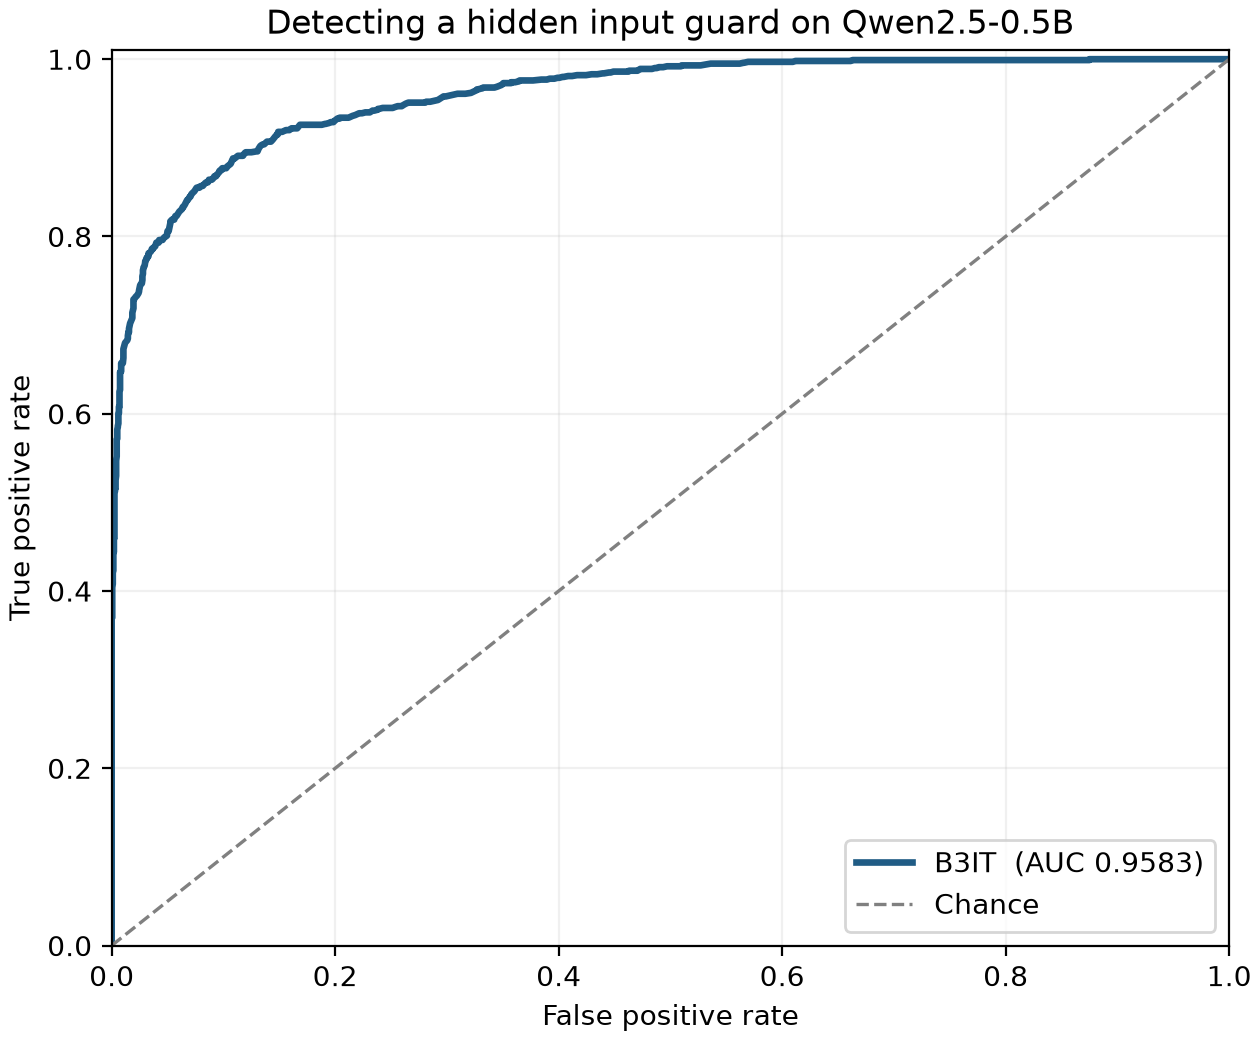

STEP 15 COMPLETE | 11.4 seconds


In [17]:
from pathlib import Path
import os
import subprocess
import time
from IPython.display import Image, display

root = Path("/workspace/B3IT_Hidden_Input_Guard")
script = root / "scripts/plot_hidden_guard.py"

script.write_text('''
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_curve

root = Path(__file__).resolve().parents[1]
summary = json.loads((root / "results/scoring/hidden_guard_b3it.json").read_text())
raw = json.loads((root / summary["raw_scores"]).read_text())
h0 = raw["h0_stats"]["stats"]
h1 = raw["h1_stats"]["stats"]
assert len(h0) == 2000 and len(h1) == 1000

fpr, tpr, _ = roc_curve([0] * len(h0) + [1] * len(h1), h0 + h1)
area = auc(fpr, tpr)
assert math.isclose(area, summary["roc_auc"], abs_tol=1e-10)

out = root / "results/figures"
out.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(6.3, 5.2), layout="constrained")
ax.plot(fpr, tpr, color="#205c85", linewidth=2.4, label=f"B3IT  (AUC {area:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1.2, label="Chance")
ax.set(
    title="Detecting a hidden input guard on Qwen2.5-0.5B",
    xlabel="False positive rate",
    ylabel="True positive rate",
    xlim=(0, 1), ylim=(0, 1.01),
)
ax.grid(alpha=0.18)
ax.legend(loc="lower right")
for ext in ("png", "pdf"):
    fig.savefig(out / f"hidden_guard_roc.{ext}", dpi=200)
plt.close(fig)
print(f"Verified ROC-AUC: {area:.8f}")
print("Figures saved in:", out)
'''.lstrip())

start = time.monotonic()
subprocess.run(
    [str(root / ".venv/bin/python"), str(script)],
    cwd=root, env={**os.environ, "MPLBACKEND": "Agg"}, check=True,
)
display(Image(filename=str(root / "results/figures/hidden_guard_roc.png")))
print(f"STEP 15 COMPLETE | {time.monotonic() - start:.1f} seconds")